In [26]:
# Imports + SQL connection
import uuid
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from lifetimes.fitters.modified_beta_geo_fitter import ModifiedBetaGeoFitter
from lifetimes.fitters.gamma_gamma_fitter import GammaGammaFitter
from lifetimes.utils import calibration_and_holdout_data
from lifetimes.plotting import (
    plot_period_transactions,
    plot_calibration_purchases_vs_holdout_purchases,
    plot_frequency_recency_matrix,
    plot_probability_alive_matrix)

# =========================
# CONFIG
# =========================
SERVER_NAME = r"DESKTOP-3DLKDPK"   # change if needed (e.g. DESKTOP-3DLKDPK\SQLEXPRESS)
DB_NAME = "AdventureWorks2025_CustomerDW"

ENGINE_STR = (
    f"mssql+pyodbc://@{SERVER_NAME}/{DB_NAME}"
    "?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
)
engine = create_engine(ENGINE_STR, fast_executemany=True)

run_id = str(uuid.uuid4())
print("Run ID:", run_id)


Run ID: 42f34019-e8bc-4ae5-9123-77464eb559ff


In [15]:
# Extract BTYD inputs from Gold
sql = """
SELECT
    customer_key,
    observation_date,
    duration_holdout,
    frequency,
    recency,
    T,
    monetary_value,
    COALESCE(frequency_holdout,0) AS frequency_holdout
FROM gold.fact_customer_btyd_inputs;
"""
df = pd.read_sql(sql, engine)
print("Input rows:", len(df))

Input rows: 16300


In [16]:
#  Basic data checks
num_cols = ["duration_holdout","frequency","recency","T","monetary_value","frequency_holdout"]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=["customer_key","observation_date","frequency","recency","T"])
df = df[(df["frequency"] >= 0) & (df["recency"] >= 0) & (df["T"] >= 0) & (df["recency"] <= df["T"])].copy()
df["monetary_value"] = df["monetary_value"].fillna(0)
df["frequency_holdout"] = df["frequency_holdout"].fillna(0)
print("Clean rows:", len(df))

Clean rows: 16300


In [17]:
# Fit BG/NBD model
mbgf = ModifiedBetaGeoFitter(penalizer_coef=0.001)
mbgf.fit(df["frequency"], df["recency"], df["T"])

df["p_alive_raw"] = mbgf.conditional_probability_alive(df["frequency"], df["recency"], df["T"])


In [18]:
# Fit Gamma-Gamma model
gg_train = df[(df["frequency"] > 0) & (df["monetary_value"] > 0)].copy()
if len(gg_train) > 50:
    ggf = GammaGammaFitter(penalizer_coef=0.001)
    ggf.fit(gg_train["frequency"], gg_train["monetary_value"])
    df["expected_avg_order_value"] = np.nan
    m = (df["frequency"] > 0) & (df["monetary_value"] > 0)
    df.loc[m, "expected_avg_order_value"] = ggf.conditional_expected_average_profit(
        df.loc[m, "frequency"], df.loc[m, "monetary_value"]
    )
    fallback_aov = max(gg_train["monetary_value"].median(), 1.0)
    df["expected_avg_order_value"] = df["expected_avg_order_value"].fillna(fallback_aov)
else:
    fallback_aov = max(df.loc[df["monetary_value"] > 0, "monetary_value"].median(), 1.0)
    df["expected_avg_order_value"] = fallback_aov

In [19]:
# If model output is too compressed, spread with recency signal
days_since_last_cal_purchase = (df["T"] - df["recency"]).clip(lower=0)

if (df["p_alive_raw"].nunique() < 20) or (df["p_alive_raw"].std() < 1e-6):
    # fallback signal for one-time / dormant cases
    recency_signal = 1 - (days_since_last_cal_purchase / df["T"].replace(0, 1))
    recency_signal = recency_signal.clip(0.02, 0.98)

    df["p_alive"] = np.where(
        df["frequency"] == 0,
        recency_signal,
        (0.7 * df["p_alive_raw"] + 0.3 * recency_signal).clip(0.02, 0.999)
    )
    print("Applied fallback p_alive spread logic.")
else:
    df["p_alive"] = df["p_alive_raw"].clip(0.000001, 0.999999)
    print("Using model p_alive directly.")

print(df["p_alive"].describe())
print("p_alive nunique:", df["p_alive"].nunique())

Applied fallback p_alive spread logic.
count    16300.000000
mean         0.344620
std          0.434508
min          0.020000
25%          0.020000
50%          0.020000
75%          0.903289
max          0.994000
Name: p_alive, dtype: float64
p_alive nunique: 4961


In [20]:
# Generate predictions 
df["predicted_purchases_30d"] = mbgf.conditional_expected_number_of_purchases_up_to_time(
    30, df["frequency"], df["recency"], df["T"]
)
df["predicted_purchases_90d"] = mbgf.conditional_expected_number_of_purchases_up_to_time(
    90, df["frequency"], df["recency"], df["T"]
)

df["predicted_revenue_30d"] = df["predicted_purchases_30d"] * df["expected_avg_order_value"]
df["predicted_revenue_90d"] = df["predicted_purchases_90d"] * df["expected_avg_order_value"]

# business labels
df["alive_status"] = pd.cut(
    df["p_alive"],
    bins=[-0.001, 0.30, 0.60, 0.85, 1.00],
    labels=["Likely Dead", "At Risk", "Active", "Very Active"]
).astype(str)

df["value_tier"] = pd.qcut(
    df["predicted_revenue_90d"].rank(method="first"),
    q=4,
    labels=["Low", "Medium", "High", "Top"]
).astype(str)

def action_rule(r):
    if r["alive_status"] in ("Likely Dead", "At Risk") and r["value_tier"] in ("High", "Top"):
        return "Win-Back High Value"
    if r["alive_status"] in ("Likely Dead", "At Risk"):
        return "Win-Back"
    if r["value_tier"] in ("High", "Top"):
        return "Retain & Grow"
    return "Nurture"

df["action_segment"] = df.apply(action_rule, axis=1)


In [21]:
# Build datasets
pred_out = pd.DataFrame({
    "run_id": run_id,
    "customer_key": df["customer_key"].astype(int),
    "observation_date": pd.to_datetime(df["observation_date"]).dt.date,
    "p_alive": df["p_alive"].astype(float),
    "predicted_purchases_30d": df["predicted_purchases_30d"].astype(float),
    "predicted_purchases_90d": df["predicted_purchases_90d"].astype(float),
    "predicted_revenue_30d": df["predicted_revenue_30d"].astype(float),
    "predicted_revenue_90d": df["predicted_revenue_90d"].astype(float),
    "expected_avg_order_value": df["expected_avg_order_value"].astype(float),
    "alive_status": df["alive_status"].astype(str),
    "value_tier": df["value_tier"].astype(str),
    "action_segment": df["action_segment"].astype(str),
})

eval_out = pd.DataFrame({
    "run_id": run_id,
    "customer_key": df["customer_key"].astype(int),
    "observation_date": pd.to_datetime(df["observation_date"]).dt.date,
    "actual_holdout_purchases": df["frequency_holdout"].astype(int),
    "predicted_holdout_purchases": df["predicted_purchases_90d"].astype(float),
    "actual_holdout_revenue": (df["frequency_holdout"] * df["monetary_value"]).astype(float),
    "predicted_holdout_revenue": df["predicted_revenue_90d"].astype(float),
    "absolute_error": (df["frequency_holdout"] - df["predicted_purchases_90d"]).abs().astype(float),
    "abs_pct_error": np.where(
        df["frequency_holdout"] > 0,
        ((df["frequency_holdout"] - df["predicted_purchases_90d"]).abs() / df["frequency_holdout"]),
        np.nan
    ),
    "p_alive": df["p_alive"].astype(float),
    "alive_status": df["alive_status"].astype(str),
})


In [22]:
#  Load into Gold prediction/eval tables
pred_out.to_sql(
    "fact_customer_btyd_predictions",
    schema="gold",
    con=engine,
    if_exists="append",
    index=False,
    chunksize=1000   # safe
)

eval_out.to_sql(
    "fact_customer_btyd_eval",
    schema="gold",
    con=engine,
    if_exists="append",
    index=False,
    chunksize=1000   # safe
)

-17

In [31]:
# Build lifetimes-style calibration/holdout frame from your existing df
ch = df[["frequency", "recency", "T", "frequency_holdout"]].copy()
ch = ch.rename(columns={
    "frequency": "frequency_cal",
    "recency": "recency_cal",
    "T": "T_cal",
    "frequency_holdout": "frequency_holdout"
})

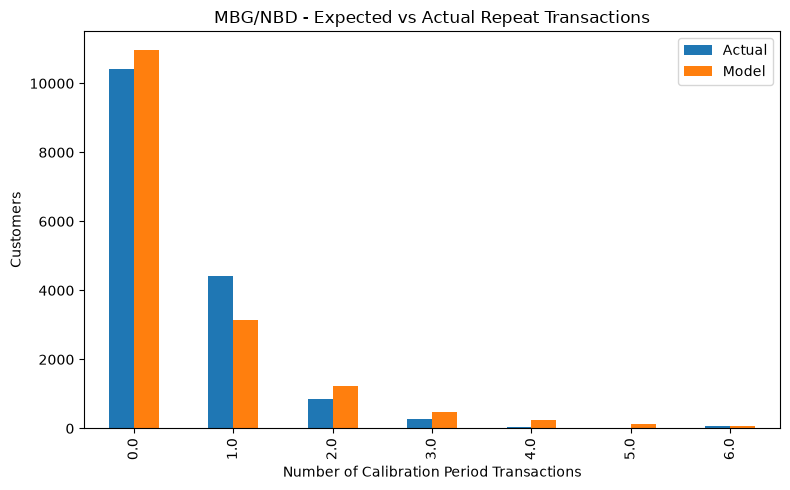

In [37]:
# 1) Expected vs Actual repeat transactions
ax = plot_period_transactions(mbgf)
ax.figure.set_size_inches(8,5)
ax.set_title("MBG/NBD - Expected vs Actual Repeat Transactions")
ax.figure.tight_layout()
plt.show()